# HW4: Stock prediction and trading strategy (Farshid Gilak)

This notebook runs the whole experiment from the full homework database: data audit, backtester accounting tests, development-period model and strategy selection, the single final test (April 1, 2016 to September 30, 2026), the benchmark comparison, and accounting and timing checks on the final run. The approach and findings are summarized in [README.md](README.md).

The code is in three modules in this folder:

| Module | Contents |
|---|---|
| `hw4_data.py` | Read-only loading, causal price and financial features, dated membership, 90-day labels |
| `hw4_model.py` | Ridge / gradient-boosting pipelines, training target, walk-forward fitting with matured labels only |
| `hw4_backtest.py` | Ledger (cash, lots, fills, fees), strategy, daily backtester, performance metrics |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
from IPython.display import display

import hw4_data as data
import hw4_model as models
import hw4_backtest as bt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

DATABASE = data.DEFAULT_DATABASE
INITIAL_CASH = 1_000_000
FEE_BPS = 10            # Per side: commission, half-spread, and impact, on every purchase and sale.
RISK_FREE = 0.02        # Sharpe hurdle only; idle cash earns 0%.
DEV_START, DEV_END = "2010-01-01", "2015-12-31"
DEV_SIGNAL, DEV_BACKTEST = pd.Timestamp("2012-12-31"), ("2013-01-02", "2015-12-31")
TEST_SIGNAL, TEST_START, TEST_END = pd.Timestamp("2016-03-31"), "2016-04-01", "2026-09-30"

## 1. Data and the prediction panel

`load_market_data` reads the database in read-only mode and puts adjusted closes on the supplied market calendar as a (date × symbol) matrix. Gaps stay missing and are never filled. Following the data guide, it quarantines the 275 zero adjusted-price rows (BHRB) and the 28 off-calendar rows.

**Signals.** Signals are made after the close on the first market session of every week (normally Monday). Each one is filled at the next session's close (normally Tuesday). I also add two extra signal sessions: December 31, 2012, so the development backtest can enter on its first day, and March 31, 2016, so the final test's first entry is at the first test close (April 1, 2016), the same close at which the benchmark is bought.

**Eligibility.** A row is eligible if the stock has a quote on the signal date, has 63 complete trailing daily returns, and belongs to the quarterly universe of the *entry* quarter, with a selection date on or before the signal close. Old rows keep their own historical membership.

**Label.** The adjusted-close return from the next-session entry to the first quoted close on or after entry + 90 calendar days, allowing at most a five-session delay. Otherwise the label is missing. `label_end` is the exit date. It is used only to decide when a label may enter training, never as a feature.

In [2]:
market = data.load_market_data(DATABASE)
display(pd.Series(market.audit, name="price rows"))
signal_dates = data.weekly_signal_dates(market.calendar, DEV_START, "2026-09-29", extra=[DEV_SIGNAL, TEST_SIGNAL])
panel = data.build_panel(market, signal_dates)
print(f"{len(signal_dates)} signal dates, {len(panel):,} eligible (date, stock) rows, "
      f"{panel.symbol.nunique():,} distinct stocks, {panel.target.isna().sum():,} rows without a completed label")
display(panel.groupby(panel.date.dt.year).agg(rows=("symbol", "size"), stocks=("symbol", "nunique"),
                                              missing_label=("target", lambda x: x.isna().sum())).T)

price_rows                15839788
invalid_adj_close_rows         275
off_calendar_rows               28
loaded_price_rows         15839485
Name: price rows, dtype: int64

875 signal dates, 1,729,612 eligible (date, stock) rows, 3,809 distinct stocks, 33,361 rows without a completed label


date,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
rows,98424,101926,104788,103306,103486,103648,105620,103507,105354,103239,102989,102586,102776,103125,104820,102909,77109
stocks,1947,2006,2066,2084,2125,2111,2102,2127,2165,2150,2233,2252,2232,2192,2181,2192,2158
missing_label,30,10,17,18,10,13,139,166,43,27,27,724,1268,1228,1339,1657,26645


**Features** (all known at the signal close):

- *Price*: 1-, 3- and 6-month momentum, 12-1 month momentum, 63-day volatility, distance from the 252-day high, 252-day beta to `^SP500TR`, and the largest daily return over the last 21 sessions.
- *Financial statements*: trailing-twelve-month gross profit / assets, ROA, net margin, accruals, debt / assets, cash / assets, and year-over-year growth in assets, quarterly sales, and shares outstanding (net issuance). These use quarterly filings only from **filing date + 1 calendar day**. A trailing-twelve-month value waits for the latest of its four filings. Filings with a non-positive lag are excluded, a late older period never replaces a newer one, and values are blanked more than 550 days after fiscal end.
- *Value and size*: earnings, book, sales and free-cash-flow yields, and log market cap. Market cap is the signal-date close × the latest known shares. I checked AAPL across its 2014 and 2020 splits: `close` and `shares_outstanding` are on the same split-adjusted basis. `volume` is not (the 2014 volume reflects only the 7:1 split), so I don't use dollar volume anywhere.
- Snapshot sector, one-hot encoded.

Each numeric feature is converted to its **percentile rank among the same date's eligible members**. This uses only same-date information, so nothing is learned across time. It also removes the effect of the extreme vendor values shown below and keeps feature scales comparable across years.

The audit below shows why ranks are needed. The raw data contains impossible values, for example a 90-day "return" of over 14,000,000% for AAM while it is ranked #1 by market cap in 2011.

In [3]:
display(panel[data.NUMERIC_FEATURES + ["target"]].describe(percentiles=[.01, .5, .99]).T[["count", "1%", "50%", "99%", "max"]])
extreme = panel.loc[panel.target.gt(5)].groupby("symbol").agg(rows=("target", "size"), max_target=("target", "max"),
                                                              median_rank=("universe_rank", "median"))
print(f"{len(extreme)} stocks have a recorded 90-day return above +500%; largest:")
display(extreme.sort_values("max_target", ascending=False).head(8))
ranked = data.cross_sectional_ranks(panel)

,count,1%,50%,99%,max
mom_21,1729612.0,-0.315248,0.009259,0.381693,1.289464e+05
mom_63,1729612.0,-0.463092,0.027841,0.757779,1.396897e+05
mom_126,1714098.0,-0.562019,0.054788,1.295566,1.050743e+05
mom_252_21,1679818.0,-0.647377,0.105150,2.402447,9.935786e+04
vol_63,1729612.0,0.101797,0.318319,1.341466,2.715385e+05
drawdown_252,1694357.0,-0.735456,-0.119183,0.000000,0.000000e+00
beta_252,1693902.0,-0.019783,1.042433,2.513235,6.874548e+01
max_ret_21,1729612.0,0.008559,0.037008,0.244656,1.357692e+05
gp_to_assets,1582076.0,-0.090677,0.193347,1.091335,3.523198e+05
roa,1582451.0,-0.840053,0.030283,0.300124,7.869142e+04


31 stocks have a recorded 90-day return above +500%; largest:


,rows,max_target,median_rank
symbol,,,
AAM,4,141144.833333,1.0
VBIV,13,816.214030,1888.0
LCI,13,29.616471,816.0
PALT,13,23.733333,1925.0
COEP,10,19.258193,1265.5
FBC,15,19.212766,1896.0
BMNR,10,15.284848,1478.0
MULN,1,12.960000,1973.0


**Price-sanity screen for purchases.** A stock is not bought if its adjusted close moved by more than a factor of 4 in a single session (|log return| > log 4) during the trailing 252 sessions. This uses only information available at the signal close. It removes ticker-reuse and unit errors like AAM's, plus a small number of genuine extreme movers. It does not affect positions already held.

In [4]:
panel["tradable"] = panel.max_abs_logret_252.le(np.log(4))
ranked["tradable"] = panel.tradable
print(f"Rows failing the screen: {(~panel.tradable).mean():.2%}")

Rows failing the screen: 0.24%


## 2. Checking the backtester's accounting by hand

Before trusting a full run, I'll test the backtester on a tiny market I can calculate by hand. It uses the real market calendar from December 2020 to May 2021, three made-up stocks, a 10 bp fee, and a strategy that submits scripted orders.

| Event | Hand calculation |
|---|---|
| Signal Thu 2020-12-31 → buy \$10,000 of A at 100 on Mon 2021-01-04 | units = 10,000 / (100 × 1.001) = 99.9001; fee = 9.9900; cash = 990,000 |
| Signal Tue 2021-01-05 → buy \$20,000 of B at 50 on Wed 2021-01-06 | units = 20,000 / (50 × 1.001) = 399.6004; cash = 970,000 |
| Signal Thu 2021-01-07 → buy C on Fri 2021-01-08, but C has no quote that day | rejected, cash unchanged |
| A's lot is due Sun 2021-04-04 (90 days), a weekend | sold at the next session, Mon 2021-04-05, at 110: proceeds = 99.9001 × 110 × 0.999 = 10,978.02 |
| B's lot is due Tue 2021-04-06, but B has no quote that day | marked at its last price (40), stale; sold Wed 2021-04-07 at 45: proceeds = 399.6004 × 45 × 0.999 = 17,964.04 |
| Final cash | 1,000,000 − 30,000 + 10,978.02 + 17,964.04 = 998,942.06 |
| NAV on 2021-03-01 (A = 110, B = 40) | 970,000 + 99.9001 × 110 + 399.6004 × 40 = 996,973.03 |

In [5]:
class ScriptedStrategy(bt.Strategy):
    def __init__(self, orders):
        self.orders = {pd.Timestamp(k): pd.Series(v, dtype=float) for k, v in orders.items()}

    def generate_orders(self, signal_date, execution_date, snapshot):
        return self.orders.get(signal_date, pd.Series(dtype=float))


toy_calendar = market.calendar[(market.calendar >= "2020-12-01") & (market.calendar <= "2021-05-28")]
toy = pd.DataFrame(index=toy_calendar, columns=["A", "B", "C"], dtype=float)
toy["A"] = np.where(toy.index < "2021-02-01", 100., 110.)
toy["B"] = np.where(toy.index < "2021-03-01", 50., np.where(toy.index < "2021-04-07", 40., 45.))
toy.loc["2021-04-06", "B"] = np.nan
toy["C"] = 30.
toy.loc["2021-01-08", "C"] = np.nan
toy_benchmark = market.benchmark.loc[toy_calendar]

toy_strategy = ScriptedStrategy({"2020-12-31": {"A": 10_000}, "2021-01-05": {"B": 20_000}, "2021-01-07": {"C": 5_000}})
toy_run = bt.Backtester(toy, toy_benchmark, toy_strategy, bt.Ledger(INITIAL_CASH, fee_bps=10)).run("2021-01-04", "2021-05-28")
display(toy_run.fills)
display(toy_run.diagnostics)

h = toy_run.history
units_a, units_b = 10_000 / (100 * 1.001), 20_000 / (50 * 1.001)
assert np.isclose(h.loc["2021-01-04", "cash"], 990_000) and np.isclose(h.loc["2021-01-06", "cash"], 970_000)
assert np.isclose(h.loc["2021-01-08", "cash"], 970_000)
assert np.isclose(h.loc["2021-03-01", "nav"], 970_000 + units_a * 110 + units_b * 40)
sells = toy_run.fills.set_index("symbol").query("side == 'SELL'")
assert sells.loc["A", "date"] == pd.Timestamp("2021-04-05") and sells.loc["B", "date"] == pd.Timestamp("2021-04-07")
assert np.isclose(sells.loc["A", "cash_change"], units_a * 110 * 0.999)
assert h.loc["2021-04-06", "stale_holdings"] == 1
assert np.isclose(h.loc["2021-04-06", "nav"], h.loc["2021-04-06", "cash"] + units_b * 40)
expected_cash = 1_000_000 - 30_000 + units_a * 110 * 0.999 + units_b * 45 * 0.999
assert np.isclose(h.cash.iloc[-1], expected_cash) and np.isclose(h.nav.iloc[-1], expected_cash)
assert np.isclose(toy_run.pnl.realized_pnl, h.nav.iloc[-1] - INITIAL_CASH)
assert set(toy_run.diagnostics.event) == {"buy_rejected_no_quote", "exit_delayed_no_quote"}

too_much = ScriptedStrategy({"2020-12-31": {"A": 2_000_000}})
try:
    bt.Backtester(toy, toy_benchmark, too_much, bt.Ledger(INITIAL_CASH)).run("2021-01-04", "2021-01-29")
    raise AssertionError("An order larger than cash must be refused")
except ValueError as error:
    print("Refused as expected:", error)
print(f"Final toy cash {h.cash.iloc[-1]:,.2f} matches the hand calculation {expected_cash:,.2f}")

,date,signal_date,lot_id,symbol,side,price,units,notional,fee,cash_change,due_date,realized_pnl
0,2021-01-04,2020-12-31,0,A,BUY,100.0,99.9001,9990.009990,9.990010,-10000.000000,2021-04-04,0.000000
1,2021-01-06,2021-01-05,1,B,BUY,50.0,399.6004,19980.019980,19.980020,-20000.000000,2021-04-06,0.000000
2,2021-04-05,2020-12-31,0,A,SELL,110.0,99.9001,10989.010989,10.989011,10978.021978,2021-04-04,978.021978
3,2021-04-07,2021-01-05,1,B,SELL,45.0,399.6004,17982.017982,17.982018,17964.035964,2021-04-06,-2035.964036


,date,symbol,lot_id,event
0,2021-01-08,C,NaN,buy_rejected_no_quote
1,2021-04-06,B,1.0,exit_delayed_no_quote


Refused as expected: Orders on 2021-01-04 exceed the cash known at 2020-12-31
Final toy cash 998,942.06 matches the hand calculation 998,942.06


## 3. Development: choosing the model (2010–2015)

**Validation design.** I use a chronological walk-forward inside the development period, with the same refitting rule I plan to use in the test. The first model is fit after the close on December 31, 2012. After that, the model is refit at the first weekly signal of every calendar quarter, 2013–2015, on an expanding window of signals since January 1, 2010. Every fit uses only rows whose `label_end` is **strictly before** the fit date (asserted in `walk_forward` and shown in the fit audit). Each fitted model scores the signals until the next refit. Signals from 2015 complete their labels during the January–March 2016 buffer. No price after March 31, 2016 is used in development.

**Selection rule.** The model is chosen by the highest mean weekly rank IC (the Spearman correlation between the score and the realized 90-day return, across all eligible members) over 2013–2015. The candidates are:

- Ridge regression on the ranked features, with median imputation plus missing-value indicators, standardization, and one-hot sector. Ridge is a linear, heavily regularized baseline suited to a low signal-to-noise problem. I compare several penalties.
- Histogram gradient boosting (sklearn), which can find nonlinear effects and interactions and handles missing values natively.
- Two training targets: the same-date percentile rank of the 90-day return ("rank"), and the 90-day return minus the same-date mean, winsorized at the 1st and 99th percentiles of the training rows ("excess").
- A no-fit baseline: 12-1 month momentum.

Because weekly 90-day labels overlap, the naive IC t-statistic overstates significance. I show it only for comparison.

In [6]:
dev = ranked.loc[ranked.date.le(DEV_END)]
assert dev.label_end.max() <= pd.Timestamp("2016-03-31")
candidates = {
    "ridge α=1e2, rank target": (models.make_model("ridge", alpha=1e2), "rank"),
    "ridge α=1e4, rank target": (models.make_model("ridge", alpha=1e4), "rank"),
    "ridge α=1e6, rank target": (models.make_model("ridge", alpha=1e6), "rank"),
    "ridge α=1e7, rank target": (models.make_model("ridge", alpha=1e7), "rank"),
    "ridge α=1e4, excess target": (models.make_model("ridge", alpha=1e4), "excess"),
    "gradient boosting, rank target": (models.make_model("hgb"), "rank"),
    "gradient boosting, excess target": (models.make_model("hgb"), "excess"),
}
dev_scores, dev_reports, dev_audits = {}, {}, {}
for name, (estimator, target) in candidates.items():
    scores, audit, _ = models.walk_forward(dev, estimator, DEV_SIGNAL, DEV_END, target=target)
    dev_scores[name], dev_audits[name] = scores, audit
    evaluated = dev.merge(scores, on=["date", "symbol"], validate="one_to_one")
    report = models.prediction_report(evaluated)
    for year in [2013, 2014, 2015]:
        report[f"IC {year}"] = models.rank_ic(evaluated.loc[evaluated.date.dt.year.eq(year)]).mean()
    dev_reports[name] = report
momentum = dev.loc[dev.date.ge(DEV_SIGNAL)].assign(score=lambda x: x.mom_252_21.fillna(0.5))
report = models.prediction_report(momentum)
for year in [2013, 2014, 2015]:
    report[f"IC {year}"] = models.rank_ic(momentum.loc[momentum.date.dt.year.eq(year)]).mean()
dev_reports["12-1 momentum (no fit)"] = report
dev_table = pd.DataFrame(dev_reports).T
display(dev_table.round(4))
chosen_model = dev_table.drop(index="12-1 momentum (no fit)").mean_rank_IC.idxmax()
print("Chosen model:", chosen_model)
display(dev_audits[chosen_model])

,mean_rank_IC,naive_IC_t_stat,share_IC_positive,top25_mean_excess_90d,top25_median_excess_90d,signal_dates,IC 2013,IC 2014,IC 2015
"ridge α=1e2, rank target",0.0361,5.6802,0.6943,0.0017,0.0015,157.0,-0.0205,0.0443,0.0841
"ridge α=1e4, rank target",0.0383,5.9774,0.7006,0.0023,0.0020,157.0,-0.0183,0.0471,0.0856
"ridge α=1e6, rank target",0.0506,5.9484,0.6879,0.0087,0.0060,157.0,-0.0273,0.0821,0.0964
"ridge α=1e7, rank target",0.0579,5.9374,0.6433,0.0044,0.0027,157.0,-0.0353,0.0938,0.1148
"ridge α=1e4, excess target",0.0012,0.2660,0.4841,0.0038,-0.0029,157.0,0.0151,-0.0283,0.0153
"gradient boosting, rank target",0.0104,2.1069,0.5732,-0.0258,-0.0340,157.0,-0.0148,0.0084,0.0354
"gradient boosting, excess target",-0.0020,-0.6701,0.5350,0.0151,-0.0072,157.0,-0.0118,0.0029,0.0028
12-1 momentum (no fit),0.0334,3.7885,0.6497,0.0276,-0.0634,157.0,0.0410,-0.0140,0.0720


Chosen model: ridge α=1e7, rank target


,fit_date,train_rows,first_train_signal,last_train_signal,last_train_label_end,first_scored_signal,last_scored_signal,scored_rows
0,2012-12-31,277363,2010-01-04,2012-09-24,2012-12-24,2012-12-31,2013-03-25,25764
1,2013-04-01,303112,2010-01-04,2012-12-24,2013-03-26,2013-04-01,2013-06-24,25795
2,2013-07-01,328875,2010-01-04,2013-03-25,2013-06-24,2013-07-01,2013-09-30,27852
3,2013-10-07,356646,2010-01-04,2013-07-01,2013-10-01,2013-10-07,2013-12-30,25864
4,2014-01-06,382506,2010-01-04,2013-09-30,2013-12-30,2014-01-06,2014-03-31,25865
5,2014-04-07,408369,2010-01-04,2013-12-30,2014-03-31,2014-04-07,2014-06-30,25842
6,2014-07-07,434224,2010-01-04,2014-03-31,2014-06-30,2014-07-07,2014-09-29,25897
7,2014-10-06,460066,2010-01-04,2014-06-30,2014-09-29,2014-10-06,2014-12-29,25882
8,2015-01-05,485963,2010-01-04,2014-09-29,2014-12-29,2015-01-05,2015-03-30,25890
9,2015-04-06,511845,2010-01-04,2014-12-29,2015-03-30,2015-04-06,2015-06-29,25946


What did the chosen model learn? The standardized coefficients of the last development fit (October 2015) show which ranked features push a prediction up or down.

In [7]:
estimator, target = candidates[chosen_model]
last_fit = dev_audits[chosen_model].fit_date.iloc[-1]
train = dev.loc[dev.date.lt(last_fit) & dev.label_end.lt(last_fit) & dev.target.notna()]
fitted = estimator.fit(train[data.FEATURES], models.training_target(train, target))
coefficients = pd.Series(fitted.named_steps["model"].coef_,
                         index=fitted.named_steps["preprocess"].get_feature_names_out()).rename(lambda s: s.split("__")[1])
display(coefficients.loc[data.NUMERIC_FEATURES].sort_values().to_frame("coefficient").T.round(5))

,vol_63,max_ret_21,share_growth,cash_to_assets,mom_126,mom_63,book_to_market,mom_21,accruals,beta_252,net_margin,filing_age_days,asset_growth,roa,mom_252_21,log_mcap,earnings_yield,debt_to_assets,sales_growth,gp_to_assets,fcf_yield,sales_to_price,drawdown_252
coefficient,-0.00061,-0.00053,-0.00039,-0.00037,-0.00012,-0.00005,-0.00001,0.00001,0.00002,0.00013,0.00015,0.00019,0.00022,0.00035,0.00036,0.00038,0.00039,0.00041,0.00042,0.00049,0.00049,0.00051,0.00051


## 4. Development: choosing the trading rules

**Fixed rules, chosen in advance rather than tuned:**

- Weekly entries are filled at the close after the signal, and every lot is held for 90 calendar days. Because 90 days is 12 weeks and 6 days, a Tuesday lot matures on a Monday. It is sold at Monday's close, and that cash is available for the Monday signal and the Tuesday entry.
- Ramp-up: the first 13 weekly entries each spend cash / (entries left in the ramp), which builds 13 equal cohorts. After that, each entry spends all available cash, mostly the proceeds of the lots that just matured. The budget is split equally over the top N names.
- Concentration limits measured on NAV at the signal close: at most 5% in one stock (summed across lots) and 30% in one snapshot sector. A name blocked by a cap is replaced by the next-ranked name. Purchases skip the price-sanity screen's failures.
- Costs: 10 bp of the traded value on every purchase and sale, deducted from cash. Entry fees are paid inside the budget. Idle cash earns 0%.

**Tuned (on development only):** the number of names per entry, N ∈ {25, 50, 100}, and a size screen on the dated universe rank ∈ {≤500, ≤1000, ≤2000}. The rule is to choose the **highest development Sharpe ratio**, using the chosen model's walk-forward scores over the development backtest (January 2, 2013 – December 31, 2015, open lots valued at the December 31, 2015 close).

In [8]:
def score_table(scores, frame):
    return scores.merge(frame[["date", "symbol", "universe_rank", "tradable"]], on=["date", "symbol"], validate="one_to_one")


def run_strategy(scores, start, end, top_n, max_rank, fee_bps=FEE_BPS):
    strategy = bt.TopScoreStrategy(scores, market.sectors, top_n=top_n, max_rank=max_rank, fee_bps=fee_bps)
    ledger = bt.Ledger(INITIAL_CASH, fee_bps=fee_bps)
    return bt.Backtester(market.adj_close, market.benchmark, strategy, ledger).run(start, end)


dev_trading_scores = score_table(dev_scores[chosen_model], dev)
grid = []
for top_n in [25, 50, 100]:
    for max_rank in [500, 1000, 2000]:
        run = run_strategy(dev_trading_scores, *DEV_BACKTEST, top_n=top_n, max_rank=max_rank)
        metrics = bt.compare(run, RISK_FREE)
        grid.append({"top_n": top_n, "max_rank": max_rank, **metrics.strategy.to_dict(),
                     "average_cash_share": (run.history.cash / run.history.nav).iloc[1:].mean()})
grid = pd.DataFrame(grid)
display(grid.round(4))
print("S&P 500 TR over the same development backtest:")
display(metrics["S&P 500 TR"].round(4).to_frame().T)
best = grid.loc[grid.Sharpe.idxmax()]
CONFIG = {"model": chosen_model, "top_n": int(best.top_n), "max_rank": int(best.max_rank)}
print("Chosen trading rules:", CONFIG)

,top_n,max_rank,final_value,total_return,CAGR,max_drawdown,annualized_volatility,Sharpe,average_cash_share
0,25,500,1.450665e+06,0.4507,0.1321,-0.1094,0.1179,0.9427,0.0564
1,25,1000,1.395958e+06,0.3960,0.1177,-0.1145,0.1232,0.8037,0.0564
2,25,2000,1.464953e+06,0.4650,0.1358,-0.1028,0.1183,0.9682,0.0567
3,50,500,1.430522e+06,0.4305,0.1269,-0.1026,0.1172,0.9084,0.0562
4,50,1000,1.428993e+06,0.4290,0.1265,-0.1030,0.1209,0.8810,0.0561
5,50,2000,1.448795e+06,0.4488,0.1316,-0.0947,0.1184,0.9360,0.0562
6,100,500,1.409243e+06,0.4092,0.1212,-0.1063,0.1174,0.8644,0.0562
7,100,1000,1.398387e+06,0.3984,0.1183,-0.1048,0.1199,0.8274,0.0560
8,100,2000,1.409198e+06,0.4092,0.1212,-0.0968,0.1187,0.8559,0.0561


S&P 500 TR over the same development backtest:


,final_value,total_return,CAGR,max_drawdown,annualized_volatility,Sharpe
S&P 500 TR,1.487843e+06,0.4878,0.1417,-0.1204,0.1272,0.9494


Chosen trading rules: {'model': 'ridge α=1e7, rank target', 'top_n': 25, 'max_rank': 2000}


## 5. Frozen experiment

Everything is fixed from here on. The final test uses the chosen model, target, and trading rules. The refit schedule is the same as in development: an initial fit after the close on March 31, 2016, then a refit at the first weekly signal of each calendar quarter from July 2016 onward. Each refit uses an expanding window of signals since 2010 and only labels that ended before the refit date. That includes test-period outcomes as they complete. The test is run once.

In [9]:
estimator, target = candidates[CONFIG["model"]]
FROZEN = {**CONFIG, "target": target, "features": data.FEATURES, "refit": "quarterly, expanding window, label_end < fit date",
          "cohorts": 13, "name_cap": 0.05, "sector_cap": 0.30, "price_screen": "max |log return| over 252 sessions <= log 4",
          "fee_bps_per_side": FEE_BPS, "cash_interest": 0.0, "initial_cash": INITIAL_CASH,
          "first_signal": str(TEST_SIGNAL.date()), "test": (TEST_START, TEST_END)}
display(pd.Series(FROZEN, dtype=object))
test_scores, test_audit, _ = models.walk_forward(ranked, estimator, TEST_SIGNAL, pd.Timestamp("2026-09-29"), target=target)
assert (test_audit.last_train_label_end < test_audit.fit_date).all()
assert (test_audit.fit_date <= test_audit.first_scored_signal).all()
display(test_audit)

model                                        ridge α=1e7, rank target
top_n                                                              25
max_rank                                                         2000
target                                                           rank
features            [mom_21, mom_63, mom_126, mom_252_21, vol_63, ...
refit               quarterly, expanding window, label_end < fit date
cohorts                                                            13
name_cap                                                         0.05
sector_cap                                                        0.3
price_screen              max |log return| over 252 sessions <= log 4
fee_bps_per_side                                                   10
cash_interest                                                     0.0
initial_cash                                                  1000000
first_signal                                               2016-03-31
test                

,fit_date,train_rows,first_train_signal,last_train_signal,last_train_label_end,first_scored_signal,last_scored_signal,scored_rows
0,2016-03-31,615480,2010-01-04,2015-12-28,2016-03-28,2016-03-31,2016-06-27,27909
1,2016-07-05,643324,2010-01-04,2016-03-31,2016-06-30,2016-07-05,2016-09-26,25866
2,2016-10-03,669171,2010-01-04,2016-06-27,2016-09-26,2016-10-03,2016-12-27,25933
3,2017-01-03,695036,2010-01-04,2016-09-26,2016-12-27,2017-01-03,2017-03-27,25875
4,2017-04-03,720961,2010-01-04,2016-12-27,2017-03-28,2017-04-03,2017-06-26,25896
5,2017-07-03,746790,2010-01-04,2017-03-27,2017-06-26,2017-07-03,2017-09-25,25843
6,2017-10-02,772635,2010-01-04,2017-06-26,2017-09-25,2017-10-02,2017-12-26,25893
7,2018-01-02,798435,2010-01-04,2017-09-25,2017-12-26,2018-01-02,2018-03-26,25853
8,2018-04-02,824302,2010-01-04,2017-12-26,2018-03-27,2018-04-02,2018-06-25,25880
9,2018-07-02,850150,2010-01-04,2018-03-26,2018-06-25,2018-07-02,2018-09-24,25813


## 6. Final test: strategy vs. `^SP500TR`

Both portfolios start with \$1,000,000 in cash at the March 31, 2016 close. The benchmark buys `^SP500TR` at the first test close (April 1, 2016), and the strategy makes its first purchases at that same close. Both are valued every session through September 30, 2026. Open lots are included at their September 30 marks, and no later prices are used. CAGR uses calendar days / 365.25. The Sharpe ratio uses daily simple returns in excess of a 2% annual rate converted to a daily rate, annualized by √252.

In [10]:
test_trading_scores = score_table(test_scores, ranked)
result = run_strategy(test_trading_scores, TEST_START, TEST_END, CONFIG["top_n"], CONFIG["max_rank"])
history = result.history
assert history.index[-1] == pd.Timestamp(TEST_END) and history.index[1] == pd.Timestamp(TEST_START)
comparison = bt.compare(result, RISK_FREE)
comparison["difference"] = comparison.strategy - comparison["S&P 500 TR"]
display(comparison.round(4))
s, b = comparison.strategy, comparison["S&P 500 TR"]
verdict = "beat" if s.final_value > b.final_value else "did not beat"
print(f"The strategy {verdict} the benchmark: final value ${s.final_value:,.0f} vs ${b.final_value:,.0f} "
      f"({s.final_value - b.final_value:+,.0f}); CAGR {s.CAGR:.2%} vs {b.CAGR:.2%} ({(s.CAGR - b.CAGR) * 100:+.2f} pp); "
      f"Sharpe {s.Sharpe:.2f} vs {b.Sharpe:.2f}; max drawdown {s.max_drawdown:.2%} vs {b.max_drawdown:.2%}.")

,strategy,S&P 500 TR,difference
final_value,2.296805e+06,4.402747e+06,-2.105942e+06
total_return,1.296800e+00,3.402700e+00,-2.105900e+00
CAGR,8.240000e-02,1.516000e-01,-6.920000e-02
max_drawdown,-3.786000e-01,-3.379000e-01,-4.070000e-02
annualized_volatility,1.528000e-01,1.782000e-01,-2.540000e-02
Sharpe,4.669000e-01,7.725000e-01,-3.056000e-01


The strategy did not beat the benchmark: final value $2,296,805 vs $4,402,747 (-2,105,942); CAGR 8.24% vs 15.16% (-6.92 pp); Sharpe 0.47 vs 0.77; max drawdown -37.86% vs -33.79%.


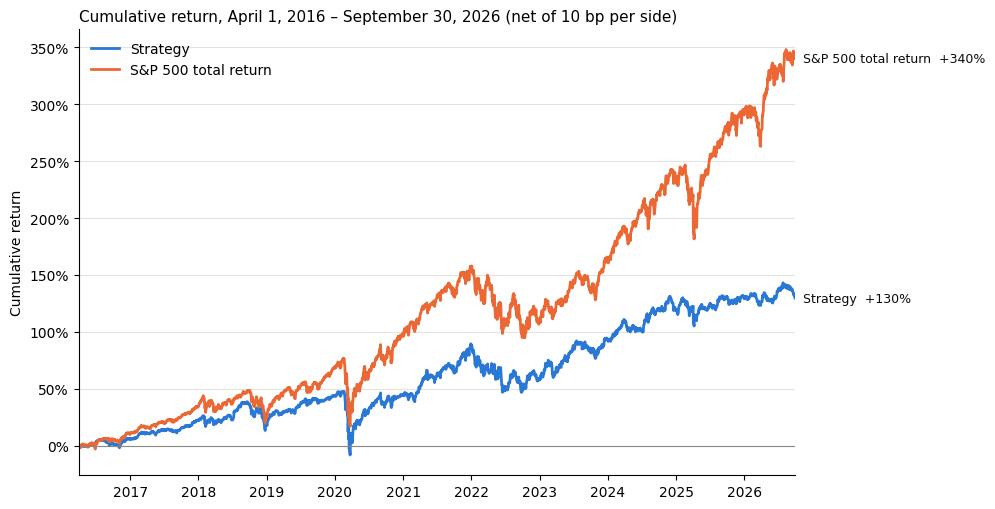

In [11]:
fig, ax = plt.subplots(figsize=(10, 5.2))
series = {"Strategy": (history.nav, "#2a78d6"), "S&P 500 total return": (history.benchmark_nav, "#eb6834")}
for label, (nav, color) in series.items():
    cumulative = nav / INITIAL_CASH - 1
    ax.plot(cumulative.index, cumulative, color=color, linewidth=2, label=label)
    ax.annotate(f"{label}  {cumulative.iloc[-1]:+.0%}", (cumulative.index[-1], cumulative.iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color="#0b0b0b",
                annotation_clip=False)
ax.axhline(0, color="#8a8984", linewidth=0.8)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Cumulative return, April 1, 2016 – September 30, 2026 (net of 10 bp per side)", loc="left", fontsize=11)
ax.set_ylabel("Cumulative return")
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.grid(axis="x", visible=False)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="upper left")
ax.set_xlim(history.index[0], history.index[-1])
fig.tight_layout()
fig.subplots_adjust(right=0.8)
fig.savefig("cumulative_returns.png", dpi=150)
plt.show()

In [12]:
year_end = history[["nav", "benchmark_nav"]].groupby(history.index.year).last()
start_row = pd.DataFrame({"nav": [INITIAL_CASH], "benchmark_nav": [INITIAL_CASH]}, index=[2015])
calendar_returns = pd.concat([start_row, year_end]).pct_change().iloc[1:].rename(
    columns={"nav": "strategy", "benchmark_nav": "S&P 500 TR"})
calendar_returns["difference"] = calendar_returns.strategy - calendar_returns["S&P 500 TR"]
calendar_returns.index.name = "year (2016 from Apr 1; 2026 to Sep 30)"
display((calendar_returns * 100).round(2).add_suffix(" (%)"))

,strategy (%),S&P 500 TR (%),difference (%)
year (2016 from Apr 1; 2026 to Sep 30),,,
2016,5.32,9.78,-4.46
2017,15.76,21.83,-6.07
2018,-2.39,-4.38,1.99
2019,20.58,31.49,-10.91
2020,1.05,18.40,-17.35
2021,30.26,28.71,1.56
2022,-16.07,-18.11,2.04
2023,22.09,26.29,-4.20
2024,13.21,25.02,-11.81


## 7. Evidence that the final run's accounting and timing are right

The checks below re-derive the account from its own records and from the raw database, independently of the backtester's running totals.

In [13]:
fills, calendar = result.fills, market.calendar
checks = {}
rebuilt_cash = INITIAL_CASH + fills.groupby("date").cash_change.sum().reindex(history.index, fill_value=0).cumsum()
checks["cash rebuilt from fills equals daily cash"] = np.allclose(rebuilt_cash, history.cash, atol=1e-6)
checks["cash never negative"] = bool(history.cash.min() >= -1e-9)
open_value = (result.open_lots.units * result.open_lots.symbol.map(result.marks)).sum()
checks["final NAV = cash + open lots at final marks"] = np.isclose(history.nav.iloc[-1], history.cash.iloc[-1] + open_value)
checks["NAV − initial = realized + unrealized PnL"] = np.isclose(
    history.nav.iloc[-1] - INITIAL_CASH, result.pnl.realized_pnl + result.pnl.unrealized_pnl)
checks["fees = 10 bp of traded notional"] = np.isclose(fills.fee.sum(), fills.notional.sum() * FEE_BPS / 1e4)

buys, sells = fills.loc[fills.side.eq("BUY")], fills.loc[fills.side.eq("SELL")]
checks["each buy's signal is the previous session"] = bool(
    (calendar[calendar.get_indexer(buys.date) - 1] == pd.DatetimeIndex(buys.signal_date)).all())
traced = buys.merge(test_trading_scores, left_on=["signal_date", "symbol"], right_on=["date", "symbol"],
                    suffixes=("", "_score"), validate="many_to_one")
checks["each buy has a score from a model fit on or before its signal"] = bool(
    len(traced) == len(buys) and traced.fit_date.le(traced.signal_date).all())
checks["each buy passed the size and price screens"] = bool(traced.universe_rank.le(CONFIG["max_rank"]).all() and traced.tradable.all())
quarter = buys.date.dt.to_period("Q").dt.start_time
members = market.membership.set_index(["quarter_start", "symbol"]).selection_date
selection = members.reindex(pd.MultiIndex.from_arrays([quarter, buys.symbol])).to_numpy()
checks["each buy was a member of its entry quarter, selected before the signal"] = bool(
    pd.notna(selection).all() and (selection <= buys.signal_date.to_numpy()).all())
checks["no purchase after the test end"] = bool(buys.date.le(TEST_END).all())

px = market.adj_close
sell_px = px.to_numpy()[calendar.get_indexer(sells.date), px.columns.get_indexer(sells.symbol)]
buy_px = px.to_numpy()[calendar.get_indexer(buys.date), px.columns.get_indexer(buys.symbol)]
checks["fill prices equal that session's adjusted close"] = np.allclose(sell_px, sells.price) and np.allclose(buy_px, buys.price)
first_quote = []
for symbol, due in zip(sells.symbol, sells.due_date):
    column = px[symbol].to_numpy()
    start = calendar.searchsorted(due)
    first_quote.append(calendar[start + np.flatnonzero(np.isfinite(column[start:]))[0]])
checks["each sale is at the first quoted close on/after its 90-day maturity"] = bool(
    (pd.DatetimeIndex(first_quote) == pd.DatetimeIndex(sells.date)).all())
held_days = (sells.date - sells.due_date + pd.Timedelta(days=90)).dt.days
checks["no lot sold before 90 calendar days"] = bool(held_days.ge(90).all())
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values())
print(f"{len(buys):,} purchases, {len(sells):,} sales, {len(result.open_lots)} open lots at the end; "
      f"holding days of sold lots: {held_days.value_counts().sort_index().to_dict()}")

,passed
cash rebuilt from fills equals daily cash,True
cash never negative,True
final NAV = cash + open lots at final marks,True
NAV − initial = realized + unrealized PnL,True
fees = 10 bp of traded notional,True
each buy's signal is the previous session,True
each buy has a score from a model fit on or before its signal,True
each buy passed the size and price screens,True
"each buy was a member of its entry quarter, selected before the signal",True
no purchase after the test end,True


8,471 purchases, 8,140 sales, 331 open lots at the end; holding days of sold lots: {90: 7712, 91: 416, 125: 1, 132: 1, 139: 1, 548: 1, 555: 1, 562: 1, 569: 1, 576: 1, 583: 1, 590: 1, 604: 1, 611: 1}


**Tracing one lot against the raw database.** I re-read the first purchase's entry and exit prices directly from DuckDB and recompute its cash flows.

In [14]:
lot = fills.loc[fills.lot_id.eq(0)].set_index("side")
with duckdb.connect(str(DATABASE), read_only=True) as con:
    raw = con.execute("SELECT date, adj_close FROM prices WHERE symbol = ? AND date IN (?, ?)",
                      [lot.loc["BUY", "symbol"], lot.loc["BUY", "date"].date(), lot.loc["SELL", "date"].date()]).fetchdf()
display(lot[["date", "signal_date", "symbol", "price", "units", "notional", "fee", "cash_change", "due_date", "realized_pnl"]])
display(raw)
entry, exit_ = raw.adj_close.iloc[0], raw.adj_close.iloc[1]
budget = -lot.loc["BUY", "cash_change"]
units = budget / (entry * (1 + FEE_BPS / 1e4))
proceeds = units * exit_ * (1 - FEE_BPS / 1e4)
assert np.isclose(units, lot.loc["BUY", "units"]) and np.isclose(proceeds, lot.loc["SELL", "cash_change"])
assert np.isclose(proceeds - budget, lot.loc["SELL", "realized_pnl"])
print(f"Budget {budget:,.2f} → {units:,.4f} units at {entry}; sold at {exit_} for {proceeds:,.2f}; PnL {proceeds - budget:,.2f}")

,date,signal_date,symbol,price,units,notional,fee,cash_change,due_date,realized_pnl
side,,,,,,,,,,
BUY,2016-04-01,2016-03-31,VZ,34.69,88.609087,3073.849228,3.073849,-3076.923077,2016-06-30,0.000000
SELL,2016-06-30,2016-03-31,VZ,36.24,88.609087,3211.193313,3.211193,3207.982119,2016-06-30,131.059042


,date,adj_close
0,2016-04-01,34.69
1,2016-06-30,36.24


Budget 3,076.92 → 88.6091 units at 34.69; sold at 36.24 for 3,207.98; PnL 131.06


## 8. Data gaps, concentration of gains, costs, and forecast quality

**Missing prices.** If a held stock has no quote, I carry its last observed close as its mark and flag it as stale. A lot past maturity without a quote is sold at the first later quoted close. When a stock's price history simply stops, which happens to many acquired or delisted names, the dataset has no delisting proceeds. I don't invent a sale. The lot stays open, valued at its last close, and that capital is never reinvested. The table below lists every lot still open at the end whose last quote is older than the final session. As a lower bound, I also show NAV with those lots written off to zero.

In [15]:
open_lots = result.open_lots.assign(last_quote=lambda x: x.symbol.map(result.last_quote),
                                    mark=lambda x: x.symbol.map(result.marks))
open_lots["value"] = open_lots.units * open_lots.mark
unresolved = open_lots.loc[open_lots.last_quote.lt(TEST_END)]
print(f"Diagnostics: {result.diagnostics.event.value_counts().to_dict()}")
print(f"Unresolved lots (price history ended while held): {len(unresolved)} lots in {unresolved.symbol.nunique()} stocks, "
      f"valued at ${unresolved.value.sum():,.0f} = {unresolved.value.sum() / history.nav.iloc[-1]:.2%} of final NAV")
display(unresolved.groupby("symbol").agg(lots=("lot_id", "size"), first_entry=("entry_date", "min"),
                                          last_quote=("last_quote", "first"), value=("value", "sum")).sort_values("value", ascending=False))
zero_recovery_nav = history.nav.iloc[-1] - unresolved.value.sum()
nav_zero = history.nav.copy()
for _, row in unresolved.iterrows():
    nav_zero.loc[nav_zero.index > row.last_quote] -= row.value
stress = bt.performance(nav_zero, RISK_FREE)
print(f"Zero-recovery lower bound: final value ${zero_recovery_nav:,.0f}, CAGR {stress.CAGR:.2%} "
      f"(vs. benchmark {comparison.loc['CAGR', 'S&P 500 TR']:.2%})")
locked = pd.Series(0., index=history.index)
for _, row in unresolved.iterrows():
    locked.loc[locked.index > row.last_quote] += row.value
locked_share = locked / history.nav
print("Share of NAV frozen in lots whose price history had ended, at each year end:")
display((locked_share.groupby(locked_share.index.year).last() * 100).round(1).rename("frozen % of NAV").to_frame().T)
held_long = sells.assign(days=(sells.date - sells.due_date).dt.days + 90).query("days > 120")
print("Sold lots held longer than 120 days (quotes resumed after a gap):")
display(held_long.groupby("symbol").agg(lots=("lot_id", "size"), first_due=("due_date", "min"), sold=("date", "max"),
                                        days=("days", "max"), realized_pnl=("realized_pnl", "sum")))

Diagnostics: {'exit_delayed_no_quote': 75483, 'no_quote_for_6_sessions': 29, 'buy_rejected_no_quote': 4}
Unresolved lots (price history ended while held): 110 lots in 27 stocks, valued at $805,763 = 35.08% of final NAV


,lots,first_entry,last_quote,value
symbol,,,,
SBBA,9,2024-12-10,2025-02-28,68650.775021
MPLXP,8,2025-12-09,2026-03-02,65753.860867
DCP,9,2023-03-21,2023-06-14,63403.312873
WBS,4,2026-06-09,2026-08-19,60388.175259
UNVR,8,2023-05-09,2023-07-31,59134.554469
BDXB,7,2023-03-14,2023-05-31,58016.848154
VRTV,8,2023-09-12,2023-11-29,55936.353363
ANTM,4,2022-04-12,2022-06-27,40312.106924
ENBA,4,2023-03-14,2023-04-14,37465.348461


Zero-recovery lower bound: final value $1,491,042, CAGR 3.88% (vs. benchmark 15.16%)
Share of NAV frozen in lots whose price history had ended, at each year end:


date,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
frozen % of NAV,0.0,3.2,3.2,2.7,2.7,2.0,7.5,23.4,23.8,28.0,35.1


Sold lots held longer than 120 days (quotes resumed after a gap):


,lots,first_due,sold,days,realized_pnl
symbol,,,,,
CCZ,3,2025-03-31,2025-05-19,139,530.711855
MPLXP,9,2023-06-12,2024-11-14,611,-118.310413


The unresolved lots fall into three groups (names from the `universe` table): completed acquisitions or take-privates whose price history stops (e.g., DCP, UNVR, VRTV, MMP, PDCE, SAFM, PGTI, JWN, BECN); a ticker change (ANTM, whose history continues as ELV in the database); and **non-common instruments labeled as stocks**, namely exchange-traded notes, preferreds, and equity units (ENBA, TBC, SBBA, BDXB, FITBP, MPLXP, DTP), which were redeemed. Their cash proceeds are not in the data, so these lots stay at their last close and the capital is never reinvested.

**Are the gains driven by a few stocks or by bad prices?** Below are realized and open PnL by stock, and the largest single-lot returns. I check these for data errors.

In [16]:
open_pnl = (open_lots.value - open_lots.units * open_lots.entry_price - open_lots.entry_fee).groupby(open_lots.symbol).sum()
pnl_by_stock = fills.groupby("symbol").realized_pnl.sum().add(open_pnl, fill_value=0).sort_values()
total_pnl = history.nav.iloc[-1] - INITIAL_CASH
print(f"Total PnL ${total_pnl:,.0f} across {fills.symbol.nunique()} stocks; "
      f"top 10 stocks contribute ${pnl_by_stock.tail(10).sum():,.0f}, bottom 10 ${pnl_by_stock.head(10).sum():,.0f}")
display(pd.concat({"largest gains": pnl_by_stock.tail(10)[::-1], "largest losses": pnl_by_stock.head(10)}, axis=1).round(0))
sold = sells.merge(buys[["lot_id", "price", "date"]], on="lot_id", suffixes=("", "_entry"))
sold["lot_return"] = sold.price / sold.price_entry - 1
print("Distribution of realized 90-day lot returns:")
display(sold.lot_return.describe(percentiles=[.01, .05, .5, .95, .99]).to_frame().T)
display(sold.nlargest(5, "lot_return")[["symbol", "date_entry", "date", "price_entry", "price", "lot_return", "realized_pnl"]])

Total PnL $1,296,805 across 577 stocks; top 10 stocks contribute $443,423, bottom 10 $-166,907


,largest gains,largest losses
symbol,,
KDP,66355.0,NaN
HCA,61345.0,NaN
MUSA,60133.0,NaN
RS,40680.0,NaN
ENVA,39816.0,NaN
ALSN,39236.0,NaN
EBAY,34710.0,NaN
GWW,34226.0,NaN
BLDR,34016.0,NaN


Distribution of realized 90-day lot returns:


,count,mean,std,min,1%,5%,50%,95%,99%,max
lot_return,8140.0,0.026066,0.146026,-0.656313,-0.298832,-0.171848,0.023037,0.223663,0.353959,6.88764


,symbol,date_entry,date,price_entry,price,lot_return,realized_pnl
2047,KDP,2018-04-24,2018-07-23,2.67,21.06,6.887640,50859.551291
3545,EBAY,2020-04-07,2020-07-06,29.26,52.16,0.782638,6425.567775
7932,ENVA,2026-03-31,2026-06-29,135.83,235.67,0.735036,750.775906
3521,EBAY,2020-03-31,2020-06-29,27.81,47.65,0.713412,78.415281
6167,VST,2024-01-17,2024-04-16,39.39,67.27,0.707794,315.268405


**The KDP lot is a data error.** On 2018-07-10 (the Keurig–Dr Pepper Snapple merger), KDP's raw close rose about 11%, but its adjusted close jumped about 590%. The vendor applied the \$103.75 merger special dividend to KDP's adjusted history. The purchase was made in April 2018, before the jump, so no screen based on information available at the time could have excluded it. Below I measure the same lot on the raw-close basis to estimate the overstatement. The headline result above is left unchanged.

In [17]:
kdp = sold.loc[sold.symbol.eq("KDP")].nlargest(1, "lot_return").iloc[0]
raw_close = market.close["KDP"]
raw_return = raw_close.loc[kdp.date] / raw_close.loc[kdp.date_entry] - 1
display(pd.DataFrame({"adjusted close": market.adj_close["KDP"].loc["2018-07-06":"2018-07-11"],
                      "raw close": raw_close.loc["2018-07-06":"2018-07-11"]}).T)
budget = kdp.units * kdp.price_entry * (1 + FEE_BPS / 1e4)
raw_pnl = kdp.units * kdp.price_entry * (1 + raw_return) * (1 - FEE_BPS / 1e4) - budget
print(f"KDP lot {kdp.date_entry.date()} → {kdp.date.date()}: adjusted return {kdp.lot_return:+.1%} (PnL ${kdp.realized_pnl:,.0f}); "
      f"raw-close return {raw_return:+.1%} (PnL ≈ ${raw_pnl:,.0f}). First-order overstatement ≈ ${kdp.realized_pnl - raw_pnl:,.0f} "
      f"({(kdp.realized_pnl - raw_pnl) / INITIAL_CASH:.1%} of initial capital), before compounding.")

date,2018-07-06,2018-07-09,2018-07-10,2018-07-11
adjusted close,2.76,2.78,19.25,20.82
raw close,19.79,19.91,22.19,24.00


KDP lot 2018-04-24 → 2018-07-23: adjusted return +688.8% (PnL $50,860); raw-close return +26.9% (PnL ≈ $1,974). First-order overstatement ≈ $48,886 (4.9% of initial capital), before compounding.


**Transaction-cost sensitivity.** These reruns use the same frozen scores and rules with different fee levels, to see how much the conclusion depends on the cost assumption. They are not used to choose anything.

In [18]:
cost_rows = []
for bps in [0, 5, 10, 25]:
    run = result if bps == FEE_BPS else run_strategy(test_trading_scores, TEST_START, TEST_END, CONFIG["top_n"], CONFIG["max_rank"], fee_bps=bps)
    cost_rows.append({"fee_bps_per_side": bps, "fees_paid": run.pnl.total_fees, **bt.performance(run.history.nav, RISK_FREE).to_dict()})
display(pd.DataFrame(cost_rows).set_index("fee_bps_per_side").round(4))
h = history.iloc[1:]
print(f"Average cash share {(h.cash / h.nav).mean():.2%} (after ramp-up {(h.cash / h.nav).loc['2016-07-01':].mean():.2%}); "
      f"traded notional / average NAV per year {fills.notional.sum() / h.nav.mean() / 10.5:.2f}; "
      f"average open lots {h.open_lots.mean():.0f}")

,fees_paid,final_value,total_return,CAGR,max_drawdown,annualized_volatility,Sharpe
fee_bps_per_side,,,,,,,
0,0.0000,2.475165e+06,1.4752,0.0902,-0.3784,0.1530,0.5133
5,59660.4578,2.384325e+06,1.3843,0.0863,-0.3785,0.1529,0.4901
10,116696.6786,2.296805e+06,1.2968,0.0824,-0.3786,0.1528,0.4669
25,273085.0644,2.052984e+06,1.0530,0.0709,-0.3791,0.1526,0.3972


Average cash share 2.70% (after ramp-up 1.72%); traded notional / average NAV per year 6.88; average open lots 224


**Forecast quality in the test.** These are walk-forward predictions scored against completed labels only. Signals near the end that have no completed label are excluded. They are still included in NAV.

In [19]:
evaluated = ranked.merge(test_scores, on=["date", "symbol"], validate="one_to_one")
evaluated = evaluated.loc[evaluated.target.notna()]
by_year = {year: models.prediction_report(g, top_n=CONFIG["top_n"]) for year, g in evaluated.groupby(evaluated.date.dt.year)}
by_year["all (members)"] = models.prediction_report(evaluated, top_n=CONFIG["top_n"])
if CONFIG["max_rank"] < 2000:
    by_year[f"all (rank ≤ {CONFIG['max_rank']})"] = models.prediction_report(evaluated, top_n=CONFIG["top_n"], max_rank=CONFIG["max_rank"])
display(pd.DataFrame(by_year).T.round(4))
print("Last evaluated signal:", evaluated.date.max().date(), "; last label end:", evaluated.label_end.max().date())

,mean_rank_IC,naive_IC_t_stat,share_IC_positive,top25_mean_excess_90d,top25_median_excess_90d,signal_dates
2016,-0.0396,-2.1264,0.4500,-0.0337,-0.0328,40.0
2017,0.0074,0.8550,0.5577,-0.0053,-0.0106,52.0
2018,-0.0049,-0.2778,0.4340,0.0056,-0.0027,53.0
2019,0.0939,5.0880,0.7500,0.0099,0.0123,52.0
2020,-0.1430,-5.4626,0.2692,-0.0836,-0.0961,52.0
2021,0.1717,10.3589,0.9231,0.0395,0.0356,52.0
2022,0.1210,4.9451,0.7308,0.0099,0.0137,52.0
2023,0.0628,3.4180,0.6154,0.0269,0.0253,52.0
2024,0.0400,2.3343,0.6415,0.0092,0.0028,53.0
2025,-0.0106,-0.4688,0.4423,-0.0161,-0.0194,52.0


Last evaluated signal: 2026-06-29 ; last label end: 2026-09-28


## 9. Summary

The comparison table, chart, and checks above are the results. My interpretation, the risks, the limitations, and what I'd try next are in [README.md](README.md).